# Atmospheric CO₂: SSP concentration pathways

Future greenhouse-gas concentrations depend on human choices and are explored with the **Shared
Socioeconomic Pathways (SSPs)**. This notebook shows the CMIP6 CO₂ concentration of SSP1-1.9,
SSP1-2.6, SSP2-4.5, SSP3-7.0 and SSP5-8.5 to 2100 — the concentrations that drive the climate
projections of this book — together with the observed record at NOAA's Mauna Loa Observatory.

**Data**
- CMIP6 global-mean CO₂ concentrations for the historical period and the SSPs
  ([Meinshausen et al., 2020](https://doi.org/10.5194/gmd-13-3571-2020)), read from the
  [RCMIP](https://www.rcmip.org/) v5.1.0 concentration file.
- NOAA Global Monitoring Laboratory, Mauna Loa annual means
  ([gml.noaa.gov/ccgg/trends](https://gml.noaa.gov/ccgg/trends/)); see
  [Historical › Greenhouse gases](../../../historical/Regional/greenhouse_gases/co2_mauna_loa.ipynb).

The SSP series are **global means**; Mauna Loa, in the Northern Hemisphere, reads about 1–2 ppm higher.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'co2.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root.')
sys.path.insert(0, str(repo_root / 'functions'))

from co2 import download_noaa_co2, download_ssp_co2, load_noaa_co2, load_ssp_co2, plot_observed_and_ssps, ssp_table
from summary_tables import save_summary_table

## 1. Configuration and data

Files are cached under `data/ghg/` (shared with the historical notebook); set `force_download = True`
to refresh them.

In [3]:
force_download = False

data_dir = repo_root / 'data' / 'ghg'
fig_dir = repo_root / 'outputs' / 'figures' / 'global'
table_dir = repo_root / 'outputs' / 'tables' / 'global'
fig_dir.mkdir(parents=True, exist_ok=True)

noaa = load_noaa_co2(download_noaa_co2(data_dir, force=force_download))
ssp = load_ssp_co2(download_ssp_co2(data_dir, force=force_download))
ssp.loc[[2014, 2030, 2050, 2100]].round(1)

,historical,ssp119,ssp126,ssp245,ssp370,ssp585
year,,,,,,
2014,397.5,397.5,397.5,397.5,397.5,397.5
2030,NaN,434.3,439.6,444.1,451.2,451.5
2050,NaN,437.6,469.3,506.9,540.6,562.8
2100,NaN,393.5,445.6,602.8,867.2,1135.2


## 2. Observations and SSP pathways

Observed annual means at Mauna Loa with the CMIP6 historical global mean and the five SSP
concentration pathways to 2100. Under the low-emission SSP1-1.9 and SSP1-2.6 the concentration peaks
around mid-century and then declines; under SSP3-7.0 and SSP5-8.5 it keeps rising through 2100.

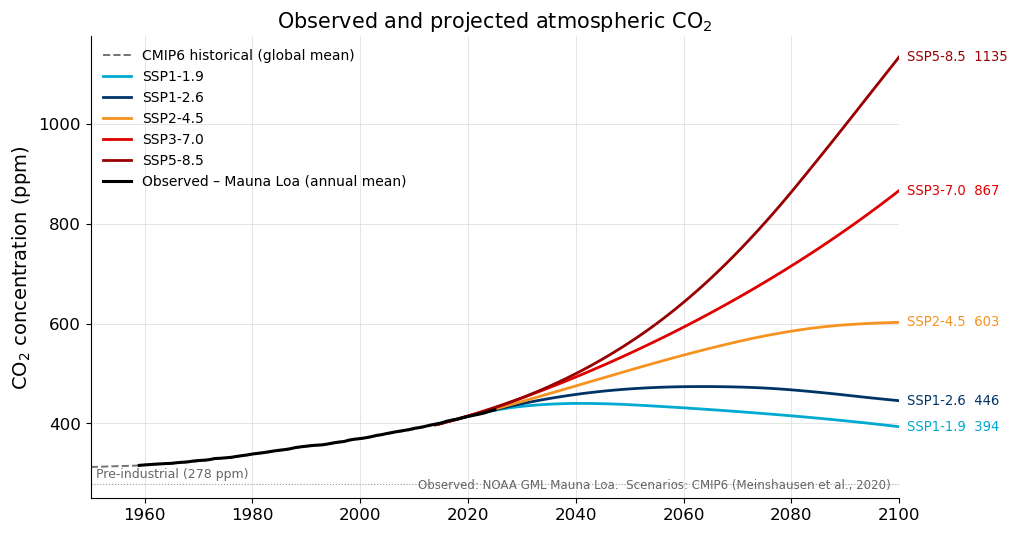

In [4]:
fig, ax = plot_observed_and_ssps(noaa, ssp)
fig.savefig(fig_dir / 'GHG_co2_observed_and_ssps.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Concentration by scenario

In [5]:
ssp_years = ssp_table(ssp)
save_summary_table(ssp_years, table_dir, 'GHG_co2_ssp_concentrations.csv')
ssp_years

Saved summary table (5 rows) to /Users/laurac/Library/Mobile Documents/com~apple~CloudDocs/Projects/CC_indicators/PICCM/CIndRA/outputs/tables/global/GHG_co2_ssp_concentrations.csv


,Scenario,2030,2050,2070,2100
0,SSP1-1.9,434,438,424,394
1,SSP1-2.6,440,469,473,446
2,SSP2-4.5,444,507,564,603
3,SSP3-7.0,451,541,652,867
4,SSP5-8.5,452,563,744,1135


## Interpretation and reproducibility notes

- The SSP concentrations are the harmonised CMIP6 inputs (Meinshausen et al., 2020); they follow
  the historical global mean to 2014 and are not updated with later observations, so the observed
  curve can diverge slightly from them.
- They are global means: Mauna Loa reads ~1–2 ppm higher and the Southern Hemisphere a few ppm lower.
- Concentrations under SSP1-1.9 and SSP1-2.6 require rapid emission reductions and net-negative CO₂
  emissions later in the century.